In [1]:

!pip install -q kaggle opencv-python-headless matplotlib numpy pandas


In [2]:

from google.colab import files

uploaded = files.upload()


Saving archive (4).zip to archive (4).zip


In [3]:

import os

print("Files currently in Colab:")
print(os.listdir("/content"))


Files currently in Colab:
['.config', 'archive (4).zip', 'sample_data']


In [4]:

import zipfile
import os

zip_path = "/content/archive (4).zip"
extract_path = "/content/drowsiness_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("\nMain folders and files:")

for item in os.listdir(extract_path):
    print(item)


Dataset extracted successfully!

Main folders and files:
dataset_new


In [5]:

import os

path = "/content/drowsiness_dataset/dataset_new"

for item in os.listdir(path):
    full = os.path.join(path, item)
    print(item, "—", len(os.listdir(full)) if os.path.isdir(full) else "file")


train — 4
test — 4


In [6]:

import os
import matplotlib.pyplot as plt
from PIL import Image

dataset_path = "/content/drowsiness_dataset/dataset_new"
extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
classes = {}

for name in os.listdir(dataset_path):
    folder = os.path.join(dataset_path, name)
    if os.path.isdir(folder):
        images = [
            os.path.join(folder, f) for f in os.listdir(folder)
            if f.lower().endswith(extensions)
        ]
        if images:
            classes[name] = images

print("Dataset summary:")
for name, images in classes.items():
    print(f"{name}: {len(images)} images")

if not classes:
    print("No class folders with images found. Check the dataset structure.")
else:
    fig, axes = plt.subplots(
        len(classes), min(3, max(map(len, classes.values()))),
        figsize=(10, 3 * len(classes)), squeeze=False
    )
    for row, (name, images) in enumerate(classes.items()):
        for col in range(axes.shape[1]):
            axes[row, col].axis("off")
            if col < len(images):
                axes[row, col].imshow(Image.open(images[col]).convert("RGB"))
                axes[row, col].set_title(name)
    plt.tight_layout()
    plt.show()


Dataset summary:
No class folders with images found. Check the dataset structure.


In [7]:

import os

base = "/content/drowsiness_dataset"

for root, dirs, files in os.walk(base):
    imgs = [f for f in files if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))]
    if imgs:
        print(root, "→", len(imgs), "images | sample:", imgs[0])


/content/drowsiness_dataset/dataset_new/train/Closed → 617 images | sample: _636.jpg
/content/drowsiness_dataset/dataset_new/train/Open → 617 images | sample: _636.jpg
/content/drowsiness_dataset/dataset_new/train/no_yawn → 616 images | sample: 1576.jpg
/content/drowsiness_dataset/dataset_new/train/yawn → 617 images | sample: 124.jpg
/content/drowsiness_dataset/dataset_new/test/Closed → 109 images | sample: _130.jpg
/content/drowsiness_dataset/dataset_new/test/Open → 109 images | sample: _130.jpg
/content/drowsiness_dataset/dataset_new/test/no_yawn → 109 images | sample: 771.jpg
/content/drowsiness_dataset/dataset_new/test/yawn → 106 images | sample: 652.jpg


In [8]:

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

DATA = "/content/drowsiness_dataset/dataset_new"
IMG_SIZE = (160, 160)
BATCH = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA + "/train",
    image_size=IMG_SIZE,
    batch_size=BATCH,
    label_mode="int"
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA + "/test",
    image_size=IMG_SIZE,
    batch_size=BATCH,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names
print("Classes:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.map(
    lambda x, y: (preprocess_input(x), y)
).prefetch(AUTOTUNE)
test_ds = test_ds.map(
    lambda x, y: (preprocess_input(x), y)
).prefetch(AUTOTUNE)

base = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(160, 160, 3)
)
base.trainable = False

model = models.Sequential([
    layers.Input(shape=(160, 160, 3)),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.25),
    layers.Dense(len(class_names), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.fit(train_ds, validation_data=test_ds, epochs=5)

loss, accuracy = model.evaluate(test_ds)
print(f"\nTest accuracy: {accuracy * 100:.2f}%")

model.save("/content/driver_drowsiness_model.keras")
print("Model saved!")


Found 2467 files belonging to 4 classes.
Found 433 files belonging to 4 classes.
Classes: ['Closed', 'Open', 'no_yawn', 'yawn']
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
78/78 ━━━━━━━━━━━━━━━━━━━━ 69s 817ms/step - accuracy: 0.7564 - loss: 0.5006 - val_accuracy: 0.8337 - val_loss: 0.2823
Epoch 2/5
78/78 ━━━━━━━━━━━━━━━━━━━━ 79s 776ms/step - accuracy: 0.8622 - loss: 0.2730 - val_accuracy: 0.8684 - val_loss: 0.2412
Epoch 3/5
78/78 ━━━━━━━━━━━━━━━━━━━━ 62s 795ms/step - accuracy: 0.8800 - loss: 0.2406 - val_accuracy: 0.8938 - val_loss: 0.2096
Epoch 4/5
78/78 ━━━━━━━━━━━━━━━━━━━━ 90s 905ms/step - accuracy: 0.9112 - loss: 0.1991 - val_accuracy: 0.9099 - val_loss: 0.1918
Epoch 5/5
78/78 ━━━━━━━━━━━━━━━━━━━━ 76s 820ms/step - accuracy: 0.9230 - loss: 0.1790 - val_accuracy: 0.9215 - val_loss: 0.1785
14/14 ━━━━━━━━━━━━━━━━━━━━ 10s 701ms/step - accuracy: 0.9215 - loss: 0.1785

Test accuracy: 92.15%
Model saved!


Saving yawn.jpg to yawn.jpg


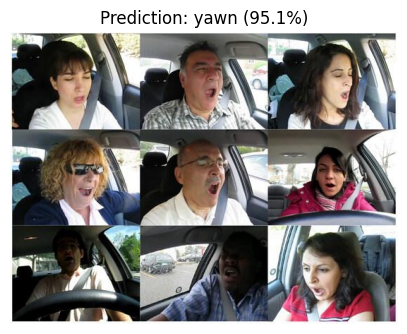

Predicted class: yawn
Confidence: 95.07%


In [9]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from google.colab import files
from PIL import Image

uploaded = files.upload()
filename = next(iter(uploaded))

img = Image.open(filename).convert("RGB").resize((160, 160))
arr = np.array(img, dtype=np.float32)
arr = tf.keras.applications.mobilenet_v2.preprocess_input(arr)
arr = np.expand_dims(arr, axis=0)

pred = model.predict(arr, verbose=0)[0]
idx = int(np.argmax(pred))
label = class_names[idx]
confidence = float(pred[idx]) * 100

plt.figure(figsize=(5, 5))
plt.imshow(Image.open(filename).convert("RGB"))
plt.axis("off")
plt.title(f"Prediction: {label} ({confidence:.1f}%)")
plt.show()

print("Predicted class:", label)
print(f"Confidence: {confidence:.2f}%")


Saving yawn 1.jpg to yawn 1.jpg


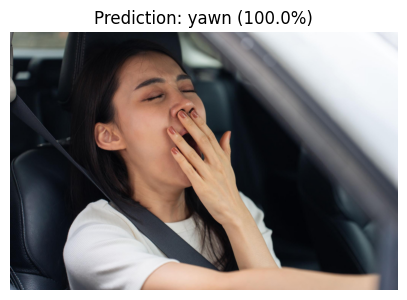

Predicted class: yawn
Confidence: 99.95%


In [10]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from google.colab import files
from PIL import Image

uploaded = files.upload()
filename = next(iter(uploaded))

img = Image.open(filename).convert("RGB").resize((160, 160))
arr = np.array(img, dtype=np.float32)
arr = tf.keras.applications.mobilenet_v2.preprocess_input(arr)
arr = np.expand_dims(arr, axis=0)

pred = model.predict(arr, verbose=0)[0]
idx = int(np.argmax(pred))
label = class_names[idx]
confidence = float(pred[idx]) * 100

plt.figure(figsize=(5, 5))
plt.imshow(Image.open(filename).convert("RGB"))
plt.axis("off")
plt.title(f"Prediction: {label} ({confidence:.1f}%)")
plt.show()

print("Predicted class:", label)
print(f"Confidence: {confidence:.2f}%")

Saving yawn.jpg to yawn (1).jpg
     DRIVER STATE ANALYSIS
Predicted class : yawn
Confidence      : 95.07%
Interpretation  : Yawning is indicated by the predicted class.

CLASS CONFIDENCE
yawn      :  95.07%
no_yawn   :   4.81%
Open      :   0.07%
Closed    :   0.04%

ASSESSMENT
Yawning-related appearance detected.
Yawning can be associated with fatigue but is not proof of it.

Limitation: this model predicts ONE class per image.
It does not independently detect squinting, eyelid droop,
or duration of eye closure.


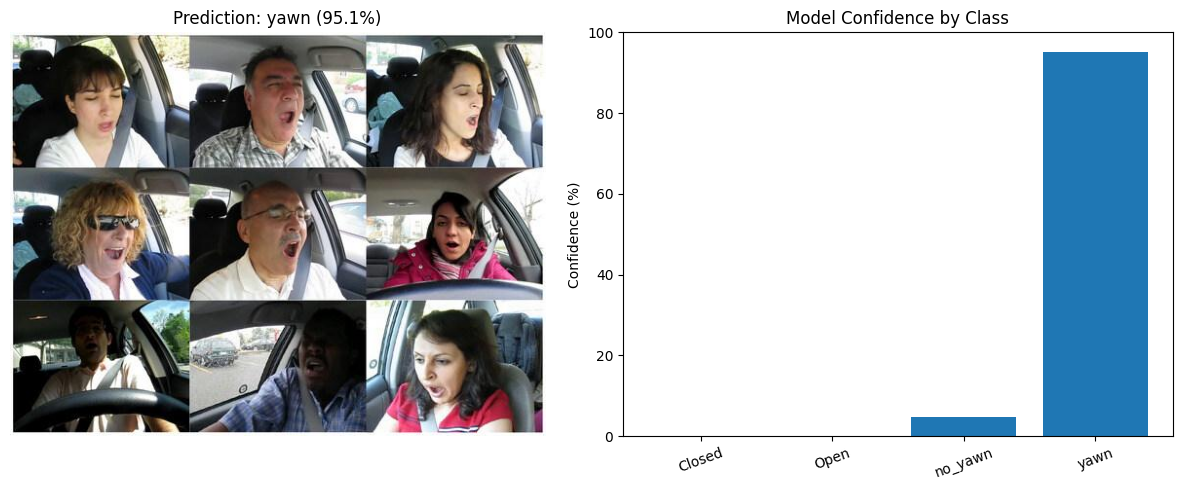

In [11]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from google.colab import files

# Upload a test image
uploaded = files.upload()
filename = next(iter(uploaded))

# Load and predict
image = Image.open(filename).convert("RGB")
img = image.resize((160, 160))
arr = np.array(img, dtype=np.float32)
arr = tf.keras.applications.mobilenet_v2.preprocess_input(arr)
arr = np.expand_dims(arr, axis=0)

pred = model.predict(arr, verbose=0)[0]
scores = dict(zip(class_names, pred))
label = max(scores, key=scores.get)
confidence = scores[label] * 100

# Interpret the model's four classes
eye_state = {
    "Closed": "Eyes appear closed in the image.",
    "Open": "Eyes appear open in the image.",
    "no_yawn": "No yawning is indicated by the predicted class.",
    "yawn": "Yawning is indicated by the predicted class."
}

print("=" * 40)
print("     DRIVER STATE ANALYSIS")
print("=" * 40)
print(f"Predicted class : {label}")
print(f"Confidence      : {confidence:.2f}%")
print(f"Interpretation  : {eye_state[label]}")

print("\nCLASS CONFIDENCE")
for name, score in sorted(scores.items(), key=lambda x: x[1], reverse=True):
    print(f"{name:10s}: {score*100:6.2f}%")

print("\nASSESSMENT")
if label == "Closed":
    print("Closed-eye appearance detected.")
    print("If persistent across video frames, this may indicate drowsiness.")
elif label == "Open":
    print("Open-eye appearance detected.")
    print("A single image cannot rule out fatigue.")
elif label == "yawn":
    print("Yawning-related appearance detected.")
    print("Yawning can be associated with fatigue but is not proof of it.")
else:
    print("No-yawn class predicted.")
    print("This alone does not establish alertness.")

print("\nLimitation: this model predicts ONE class per image.")
print("It does not independently detect squinting, eyelid droop,")
print("or duration of eye closure.")

# Display image and confidence chart
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(image)
axes[0].set_title(f"Prediction: {label} ({confidence:.1f}%)")
axes[0].axis("off")

axes[1].bar(list(scores.keys()), [v * 100 for v in scores.values()])
axes[1].set_title("Model Confidence by Class")
axes[1].set_ylabel("Confidence (%)")
axes[1].tick_params(axis="x", rotation=20)
axes[1].set_ylim(0, 100)

plt.tight_layout()
plt.show()
